In [1]:
import pandas as pd
import numpy as np

# load datasets
batch_data = pd.read_excel("../data/batch_data.xlsx")
sensor_data = pd.read_excel("../data/sensor_data.xlsx")

# preview data
print("Batch Data:")
display(batch_data.head())

print("Sensor Data:")
display(sensor_data.head())

Batch Data:


,Batch_ID,Granulation_Time,Binder_Amount,Drying_Temp,Drying_Time,Compression_Force,Machine_Speed,Lubricant_Conc,Moisture_Content,Tablet_Weight,Hardness,Friability,Disintegration_Time,Dissolution_Rate,Content_Uniformity
0,T001,15,8.5,60,25,12.5,150,1.0,2.1,199.8,95,0.65,8.2,89.3,98.7
1,T002,12,7.0,65,20,15.0,120,0.8,2.8,201.3,110,0.45,12.1,87.9,101.2
2,T003,18,9.2,55,30,10.8,180,1.2,1.9,198.5,85,0.78,6.8,91.5,97.3
3,T004,20,10.0,58,35,8.5,200,1.5,1.5,203.2,72,0.95,5.5,93.8,95.9
4,T005,10,6.5,70,18,16.2,100,0.6,3.2,202.7,125,0.38,14.8,85.1,103.5


Sensor Data:


,Batch_ID,Time_Minutes,Phase,Temperature_C,Pressure_Bar,Humidity_Percent,Motor_Speed_RPM,Compression_Force_kN,Flow_Rate_LPM,Power_Consumption_kW,Vibration_mm_s
0,T001,0,Preparation,22.844876,1.023866,39.089956,0.0,0.0,0.0,2.022778,0.152049
1,T001,1,Preparation,24.892949,1.170301,46.608042,0.0,0.0,0.0,1.164997,0.078395
2,T001,2,Preparation,26.782330,0.868381,47.701284,0.0,0.0,0.0,2.613172,0.082868
3,T001,3,Preparation,26.016792,0.992348,45.715249,0.0,0.0,0.0,1.830001,0.109149
4,T001,4,Preparation,26.865916,1.057775,43.308165,0.0,0.0,0.0,2.804104,0.195893


In [2]:
batch_data.info()
batch_data.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Batch_ID             60 non-null     object 
 1   Granulation_Time     60 non-null     int64  
 2   Binder_Amount        60 non-null     float64
 3   Drying_Temp          60 non-null     int64  
 4   Drying_Time          60 non-null     int64  
 5   Compression_Force    60 non-null     float64
 6   Machine_Speed        60 non-null     int64  
 7   Lubricant_Conc       60 non-null     float64
 8   Moisture_Content     60 non-null     float64
 9   Tablet_Weight        60 non-null     float64
 10  Hardness             60 non-null     int64  
 11  Friability           60 non-null     float64
 12  Disintegration_Time  60 non-null     float64
 13  Dissolution_Rate     60 non-null     float64
 14  Content_Uniformity   60 non-null     float64
dtypes: float64(9), int64(5), object(1)
memory 

,Granulation_Time,Binder_Amount,Drying_Temp,Drying_Time,Compression_Force,Machine_Speed,Lubricant_Conc,Moisture_Content,Tablet_Weight,Hardness,Friability,Disintegration_Time,Dissolution_Rate,Content_Uniformity
count,60.000000,60.000000,60.000000,60.00000,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000
mean,16.566667,9.011667,59.400000,28.85000,11.596667,169.166667,1.213333,2.013333,202.383333,90.416667,0.785333,8.215000,90.928333,98.336667
std,4.484877,1.841802,7.220968,8.27253,3.522565,46.437553,0.573265,0.775355,3.400258,23.466017,0.361346,3.664526,4.626859,3.951570
min,9.000000,5.800000,42.000000,15.00000,4.500000,92.000000,0.400000,0.200000,197.600000,40.000000,0.290000,2.600000,81.200000,89.800000
25%,13.000000,7.675000,54.750000,22.75000,8.650000,137.250000,0.800000,1.500000,200.025000,75.500000,0.517500,5.575000,87.550000,95.725000
50%,16.000000,8.750000,60.000000,27.50000,12.100000,161.000000,1.100000,2.100000,201.700000,92.500000,0.715000,7.950000,90.300000,98.450000
75%,20.000000,10.225000,64.250000,35.00000,14.225000,200.000000,1.600000,2.525000,203.975000,108.250000,0.912500,10.150000,94.200000,101.325000
max,27.000000,13.500000,73.000000,48.00000,18.000000,280.000000,2.800000,3.600000,213.800000,135.000000,1.920000,17.500000,99.900000,106.300000


In [3]:
# input features
X = batch_data[
[
'Granulation_Time',
'Binder_Amount',
'Drying_Temp',
'Drying_Time',
'Compression_Force',
'Machine_Speed',
'Lubricant_Conc',
'Moisture_Content',
'Tablet_Weight'
]
]

# targets
y = batch_data[
[
'Hardness',
'Friability',
'Dissolution_Rate',
'Content_Uniformity'
]
]

In [4]:
from sklearn.model_selection import train_test_split

# split data into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [5]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.multioutput import MultiOutputRegressor

rf = RandomForestRegressor(n_estimators=200, random_state=42)

model = MultiOutputRegressor(rf)

model.fit(X_train, y_train)

,estimator estimator: estimator objectAn estimator object implementing :term:`fit` and :term:`predict`.,RandomForestR...ndom_state=42)
,"n_jobs n_jobs: int or None, optional (default=None)The number of jobs to run in parallel.:meth:`fit`, :meth:`predict` and :meth:`partial_fit` (if supportedby the passed estimator) will be parallelized for each target.When individual estimators are fast to train or predict,using ``n_jobs > 1`` can result in slower performance dueto the parallelism overhead.``None`` means `1` unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all available processes / threads.See :term:`Glossary ` for more details... versionchanged:: 0.20 `n_jobs` default changed from `1` to `None`.",None
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least

In [6]:
predictions = model.predict(X_test)

In [7]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print("MAE:", mae)
print("RMSE:", rmse)

MAE: 0.6598062500000057
RMSE: 1.2135304305345342


In [8]:
import joblib

joblib.dump(model, "../models/batch_prediction_model.pkl")

['../models/batch_prediction_model.pkl']

In [9]:
from sklearn.ensemble import IsolationForest

# select sensor features
sensor_features = sensor_data[
[
'Temperature_C',
'Pressure_Bar',
'Humidity_Percent',
'Motor_Speed_RPM',
'Flow_Rate_LPM',
'Power_Consumption_kW',
'Vibration_mm_s'
]
]

# build anomaly detection model
iso_model = IsolationForest(
    n_estimators=200,
    contamination=0.05,
    random_state=42
)

# train model
iso_model.fit(sensor_features)

print("Energy anomaly model trained successfully")

Energy anomaly model trained successfully


In [10]:
sensor_data['Anomaly'] = iso_model.predict(sensor_features)

sensor_data.head()

,Batch_ID,Time_Minutes,Phase,Temperature_C,Pressure_Bar,Humidity_Percent,Motor_Speed_RPM,Compression_Force_kN,Flow_Rate_LPM,Power_Consumption_kW,Vibration_mm_s,Anomaly
0,T001,0,Preparation,22.844876,1.023866,39.089956,0.0,0.0,0.0,2.022778,0.152049,1
1,T001,1,Preparation,24.892949,1.170301,46.608042,0.0,0.0,0.0,1.164997,0.078395,1
2,T001,2,Preparation,26.782330,0.868381,47.701284,0.0,0.0,0.0,2.613172,0.082868,1
3,T001,3,Preparation,26.016792,0.992348,45.715249,0.0,0.0,0.0,1.830001,0.109149,1
4,T001,4,Preparation,26.865916,1.057775,43.308165,0.0,0.0,0.0,2.804104,0.195893,1


In [11]:
joblib.dump(iso_model, "../models/anomaly_detection_model.pkl")

['../models/anomaly_detection_model.pkl']

             Feature  Importance
1      Binder_Amount    0.150135
0   Granulation_Time    0.149943
7   Moisture_Content    0.140334
5      Machine_Speed    0.139223
4  Compression_Force    0.116111
6     Lubricant_Conc    0.099501
3        Drying_Time    0.090415
2        Drying_Temp    0.077384
8      Tablet_Weight    0.036955


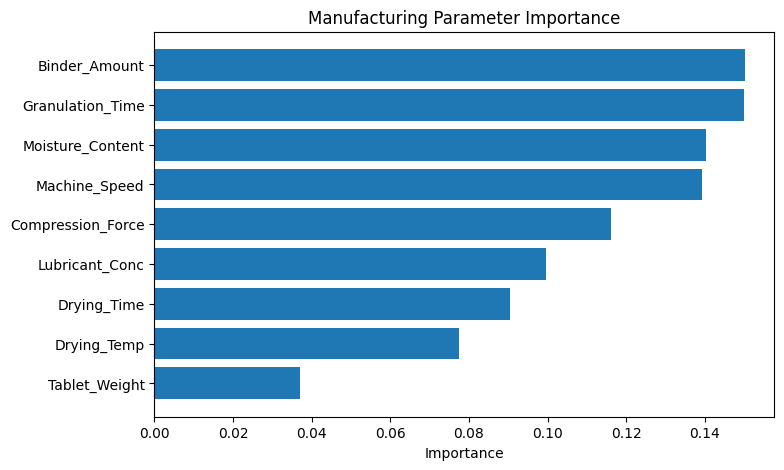

In [12]:
import matplotlib.pyplot as plt
import pandas as pd

# feature importance from the first RandomForest model
importances = model.estimators_[0].feature_importances_

features = [
'Granulation_Time',
'Binder_Amount',
'Drying_Temp',
'Drying_Time',
'Compression_Force',
'Machine_Speed',
'Lubricant_Conc',
'Moisture_Content',
'Tablet_Weight'
]

importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

print(importance_df)

# plot
plt.figure(figsize=(8,5))
plt.barh(importance_df["Feature"], importance_df["Importance"])
plt.xlabel("Importance")
plt.title("Manufacturing Parameter Importance")
plt.gca().invert_yaxis()
plt.show()

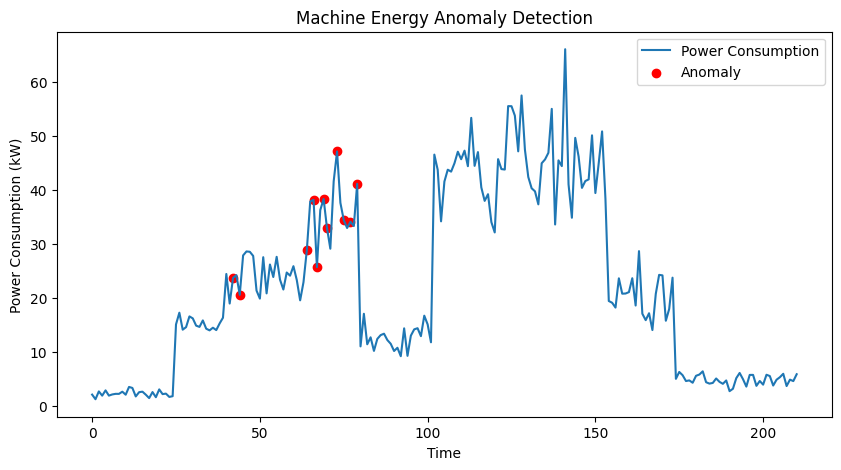

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.plot(sensor_data['Power_Consumption_kW'], label="Power Consumption")

# highlight anomalies
anomalies = sensor_data[sensor_data['Anomaly'] == -1]

plt.scatter(anomalies.index,
            anomalies['Power_Consumption_kW'],
            color='red',
            label="Anomaly")

plt.title("Machine Energy Anomaly Detection")
plt.xlabel("Time")
plt.ylabel("Power Consumption (kW)")
plt.legend()

plt.show()